# 03 · Double-lined binaries with TODCOR

**What you'll learn**

- why a single template is not enough when two stars' spectra are blended
- how TODCOR (`CCF2d`) fits both velocities and the two stars' line strengths at once
- how to read the (v1, v2) likelihood map, the amplitudes and the Cramér-Rao errors
- how to measure a whole orbit with `Observations.calc_rv_against_two_templates`
- why the window length, the taper and the continuum setting matter

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sparta import CCF1d, CCF2d, Observations
from sparta.instruments import Simulation
from sparta.instruments.simulated import component_templates
from sparta.plotting import (GREY, apply_style, mark_truth, plot_data, plot_extra, plot_model,
                             plot_points)

apply_style()

## 1. A simulated double-lined binary

Two PHOENIX stars, a 5800 K primary and a cooler 4900 K secondary, on a circular 4.3-day orbit,
observed "like HARPS" in one 200 Å window (section 5 explains the length) at signal-to-noise 50.
Each star's `amplitude` is its line dilution: the composite spectrum is
$1 + a_1\,(f_1 - 1) + a_2\,(f_2 - 1)$, so $a_1 = 0.7,\ a_2 = 0.3$ roughly mean the primary gives 70%
of the light.

In [2]:
P, K1, K2, gamma = 4.3, 45.0, 75.0, 10.0                 # days, km/s, km/s, km/s
rng = np.random.default_rng(3)
times = np.sort(rng.uniform(0, 20, 12))
v1_true = gamma + K1 * np.sin(2 * np.pi * times / P)
v2_true = gamma - K2 * np.sin(2 * np.pi * times / P)

sim = Simulation(like="HARPS", windows_A=[(5000, 5200)], times=times,
                 rv_kms=np.column_stack([v1_true, v2_true]),
                 components=[dict(teff=5800, logg=3.5, feh=0.5, vsini=4.0, amplitude=0.7),
                             dict(teff=4900, logg=4.5, vsini=2.0, amplitude=0.3)],
                 snr=50, noise="constant", seed=4)
obs = Observations(survey="SIMULATED", simulation=sim)
t1, t2 = component_templates(sim)                         # the two rest-frame models
print(f"{obs.sample_size} epochs; amplitudes injected: {obs.truth.amplitudes}")

12 epochs; amplitudes injected: [0.7 0.3]


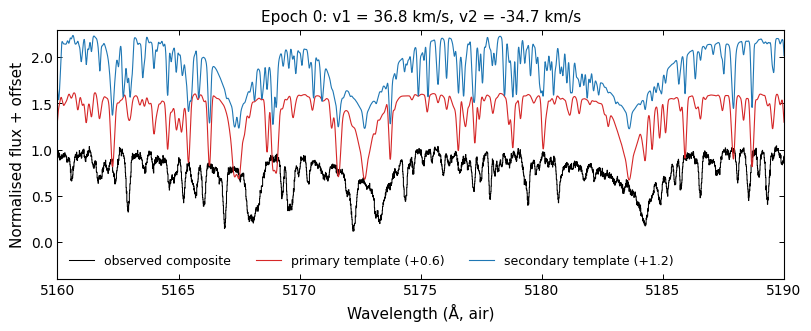

In [3]:
k = 0
fig, ax = plt.subplots()
plot_data(ax, obs.spec_list[k].wv[0], obs.spec_list[k].sp[0], label="observed composite")
plot_model(ax, t1.model.wv[0], t1.model.sp[0] + 0.6, lw=0.8, label="primary template (+0.6)")
plot_extra(ax, t2.model.wv[0], t2.model.sp[0] + 1.2, lw=0.8, label="secondary template (+1.2)")
ax.set_xlim(5160, 5190)
ax.set_ylim(-0.4, 2.3)
ax.set_xlabel("Wavelength (Å, air)")
ax.set_ylabel("Normalised flux + offset")
ax.set_title(f"Epoch {k}: v1 = {v1_true[k]:.1f} km/s, v2 = {v2_true[k]:.1f} km/s")
ax.legend(loc="lower left", ncols=3)
plt.show()

## 2. Why one template is not enough

With only the primary's template (`CCF1d`, notebook 02), the secondary's lines leak into the CCF
and pull the primary's peak. The pull is worst when the two stars' lines overlap:

In [4]:
for k in np.argsort(np.abs(v1_true - v2_true))[:3]:
    c1 = CCF1d().cross_correlate(obs.spec_list[k], t1, dv=0.3, vel_bound=120).combine().CorrCombined
    print(f"v1 - v2 = {v1_true[k] - v2_true[k]:6.1f} km/s:  CCF1d primary RV off by "
          f"{(c1['RV'] - v1_true[k]) * 1e3:7.1f} m/s (reported error {c1['eRV'] * 1e3:.1f} m/s)")

v1 - v2 =   11.0 km/s:  CCF1d primary RV off by  -269.6 m/s (reported error 17.1 m/s)
v1 - v2 =  -21.5 km/s:  CCF1d primary RV off by    45.2 m/s (reported error 17.3 m/s)
v1 - v2 =   45.7 km/s:  CCF1d primary RV off by   -46.3 m/s (reported error 17.5 m/s)


## 3. TODCOR on one epoch

TODCOR (Zucker & Mazeh 1994) models the spectrum as *both* templates, shifted to $v_1$ and
$v_2$ and scaled by $a_1$ and $a_2$, and evaluates the fit on a grid of $(v_1, v_2)$. The
amplitudes enter linearly, so at every grid node they are solved exactly; the map that remains
is a likelihood over the two velocities. The parameters used here:

- `dv=0.3`: step (km/s) of the log-λ grid the fit runs on;
- `vel_bound=120`, `dvel=2.0`: trial velocities from −120 to +120 km/s for both stars, every
  2 km/s; the peak is then refined on a fine local grid automatically;
- `alpha=0.3`, `continuum=1.0`: taper and continuum level (section 5);
- `sigma=None` (default): the noise is estimated from the fit residuals.

In [5]:
k = 0
fit = CCF2d().cross_correlate(obs.spec_list[k], t1, t2, dv=0.3, vel_bound=120, dvel=2.0,
                              alpha=0.3, continuum=1.0)
r = fit.Corr2d
print(f"v1 = {r['RV1']:8.4f} ± {r['eRV1']:.4f} km/s   (truth {v1_true[k]:8.4f})")
print(f"v2 = {r['RV2']:8.4f} ± {r['eRV2']:.4f} km/s   (truth {v2_true[k]:8.4f})")
print(f"a1 = {r['a1_best']:.3f}, a2 = {r['a2_best']:.3f}   (truth 0.7, 0.3)")
print(f"reduced chi2 = {r['chi2_red']:.3f}, correlation of the v1 and v2 errors = {r['rho12']:+.3f}")

v1 =  36.8255 ± 0.0058 km/s   (truth  36.8222)
v2 = -34.6983 ± 0.0098 km/s   (truth -34.7037)
a1 = 0.700, a2 = 0.300   (truth 0.7, 0.3)
reduced chi2 = 1.000, correlation of the v1 and v2 errors = +0.009


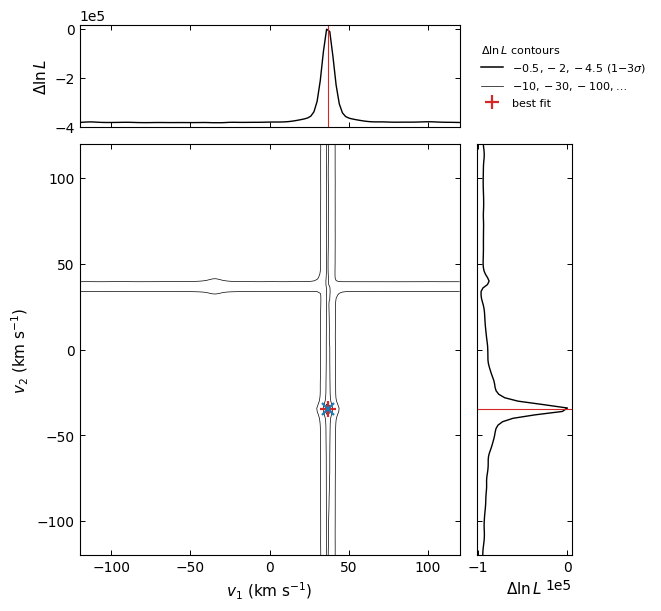

In [6]:
fig = fit.plot()
mark_truth(fig.axes[0], v1_true[k], v2_true[k])     # the map panel; blue x = the truth
plt.show()

A single, well-defined peak (red +, on the truth, blue ×). The contours are $\Delta\ln L$
below the maximum: −0.5, −2, −4.5 (1, 2, 3σ for one velocity; thick) and then −10, −30,
−100, … (thin). At this signal-to-noise the peak is far narrower than the 2 km/s grid (the
errors above are a few m/s), so the inner contours all collapse onto the +; the map shows the
global structure, and the fit refines the peak on a fine local grid. The long straight
ridges, along constant $v_1$ and constant $v_2$, are where one template alone lines up with one
of the stars (each template partly matches *both* stars, since their spectra share many lines);
only at the right crossing do both templates match.

`best_fit_spectrum` rebuilds the model at the fitted values, so the residual should look like
the injected noise, σ = 1/50 = 0.02 per native pixel; a little less, in fact, because resampling
onto the finer 0.3 km/s grid smooths the noise (notebook 01). The window ends are tapered, so we
look at the interior:

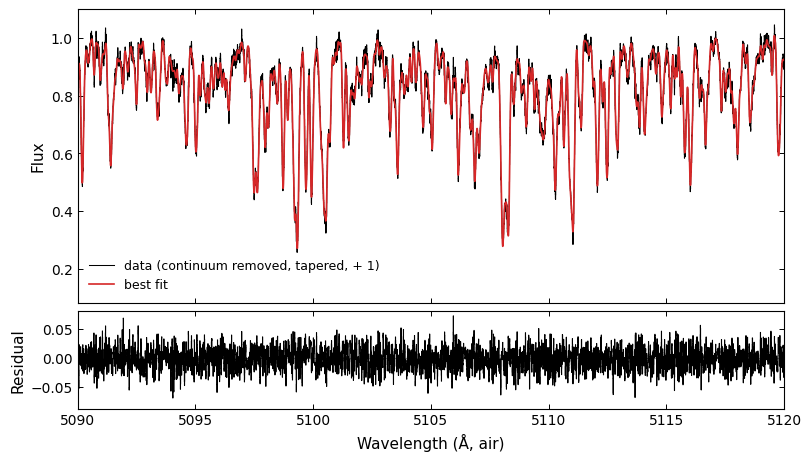

residual rms (inner 60% of the window) = 0.0186


In [7]:
wv, model, data = fit.best_fit_spectrum(0)
inner = slice(len(wv) // 5, -len(wv) // 5)               # away from the tapered ends

fig, axs = plt.subplots(2, 1, figsize=(8, 4.5), sharex=True, gridspec_kw={"height_ratios": (3, 1)})
plot_data(axs[0], wv, data, label="data (continuum removed, tapered, + 1)")
plot_model(axs[0], wv, model, label="best fit")
axs[0].set_ylabel("Flux")
axs[0].legend(loc="lower left")
axs[1].axhline(0, color=GREY, lw=0.8)
plot_data(axs[1], wv, data - model)
axs[1].set_ylabel("Residual")
axs[1].set_xlabel("Wavelength (Å, air)")
axs[1].set_xlim(5090, 5120)
plt.show()
print(f"residual rms (inner 60% of the window) = {np.std((data - model)[inner]):.4f}")

## 4. The whole orbit

`Observations.calc_rv_against_two_templates` runs one TODCOR fit per epoch (epochs are never
pooled: the velocities change between them) and stores `vels1`, `vels2`, their errors
`evels1`, `evels2` and the amplitudes `amps1`, `amps2`.

In [8]:
obs.calc_rv_against_two_templates(t1, t2, dv=0.3, vel_bound=120, dvel=2.0, alpha=0.3, continuum=1.0)

for name, vel, err, truth in [("primary", obs.vels1, obs.evels1, v1_true),
                              ("secondary", obs.vels2, obs.evels2, v2_true)]:
    oc = vel - truth
    print(f"{name:9s}: rms(O-C) = {np.std(oc) * 1e3:5.1f} m/s, median error = {np.median(err) * 1e3:5.1f} m/s")
print(f"amplitudes: a1 = {obs.amps1.mean():.3f} ± {obs.amps1.std():.3f}, "
      f"a2 = {obs.amps2.mean():.3f} ± {obs.amps2.std():.3f}")

primary  : rms(O-C) =   4.4 m/s, median error =   5.8 m/s
secondary: rms(O-C) =   9.0 m/s, median error =   9.8 m/s
amplitudes: a1 = 0.700 ± 0.001, a2 = 0.300 ± 0.001


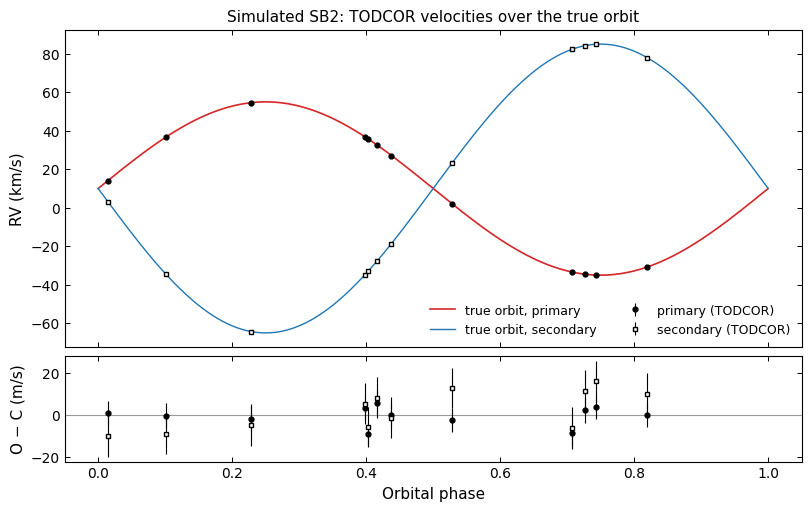

In [9]:
phase = (times % P) / P
grid = np.linspace(0, 1, 300)
fig, axs = plt.subplots(2, 1, figsize=(8, 5), sharex=True, gridspec_kw={"height_ratios": (3, 1)})
plot_model(axs[0], grid, gamma + K1 * np.sin(2 * np.pi * grid), label="true orbit, primary")
plot_extra(axs[0], grid, gamma - K2 * np.sin(2 * np.pi * grid), label="true orbit, secondary")
plot_points(axs[0], phase, obs.vels1, obs.evels1, label="primary (TODCOR)")
plot_points(axs[0], phase, obs.vels2, obs.evels2, fmt="s", mfc="white", label="secondary (TODCOR)")
axs[0].set_ylabel("RV (km/s)")
axs[0].set_title("Simulated SB2: TODCOR velocities over the true orbit")
axs[0].legend(ncols=2, loc="lower right")
axs[1].axhline(0, color=GREY, lw=0.8)
plot_points(axs[1], phase, (obs.vels1 - v1_true) * 1e3, obs.evels1 * 1e3)
plot_points(axs[1], phase, (obs.vels2 - v2_true) * 1e3, obs.evels2 * 1e3, fmt="s", mfc="white")
axs[1].set_xlabel("Orbital phase")
axs[1].set_ylabel("O − C (m/s)")
plt.show()

## 5. Window, taper and continuum

TODCOR shifts the templates with Fourier phase factors, which wrap around: a line pushed past
one end of the window re-enters at the other. On a short, line-crowded window that misfit
biases the velocities. A longer window has fewer edge lines per line in total, and a stronger
taper (`alpha`) damps the ends. And `continuum='median'` (the default) is only a proxy: the
median of an absorption spectrum sits below its continuum, which biases the amplitudes; for
continuum-normalised spectra like these, `continuum=1.0` is exact.

A noiseless test at two epochs, so any offset is bias:

In [10]:
rv_test = np.array([[30.0, -45.0], [-42.3, 51.7]])
components = [dict(teff=5800, logg=3.5, feh=0.5, vsini=4.0, amplitude=0.7),
              dict(teff=4900, logg=4.5, vsini=2.0, amplitude=0.3)]

for window, alpha, continuum in [((5000, 5050), 0.1, "median"), ((5000, 5200), 0.3, 1.0)]:
    test = Simulation(like="HARPS", windows_A=[window], times=[0.0, 1.0], rv_kms=rv_test,
                      components=components)
    test_obs = Observations(survey="SIMULATED", simulation=test)
    s1, s2 = component_templates(test)
    out = [CCF2d().cross_correlate(sp, s1, s2, dv=0.3, vel_bound=80, dvel=2.0, alpha=alpha,
                                   continuum=continuum).Corr2d for sp in test_obs.spec_list]
    bias = np.array([[o["RV1"], o["RV2"]] for o in out]) - rv_test
    amps = np.array([[o["a1_best"], o["a2_best"]] for o in out])
    print(f"{window[1] - window[0]} Å window, alpha={alpha}, continuum={continuum!r}: "
          f"largest velocity bias {np.max(np.abs(bias)) * 1e3:5.1f} m/s, "
          f"amplitudes {np.round(amps.mean(axis=0), 3)}")

50 Å window, alpha=0.1, continuum='median': largest velocity bias  15.6 m/s, amplitudes [0.696 0.297]


200 Å window, alpha=0.3, continuum=1.0: largest velocity bias   3.1 m/s, amplitudes [0.7 0.3]


Hence the 200 Å window, `alpha=0.3` and `continuum=1.0` above. (For real spectra that are not
continuum-normalised, `'median'` or a preprocessed spectrum is the practical choice.)

## Summary / next

- A one-template CCF is biased on a blended double-lined spectrum; TODCOR fits both stars.
- `CCF2d.cross_correlate` returns both RVs, their Cramér-Rao errors, the amplitudes and the
  likelihood map; on simulated data the errors match the scatter about the truth.
- `Observations.calc_rv_against_two_templates` does it epoch by epoch for a time series.
- Use long windows, a firm taper and the right continuum level to avoid edge bias.

For the mathematics (sufficient statistics, the closed-form amplitudes, combining windows), see
the deep dives in `todcor/`: `01_method`, `02_single_window_fit`, `03_multiwindow_combination`.

**Next:** `04_template_from_data_tiravel.ipynb`: building the template from the observations.